In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
from mainFunction import load_all_dataset, load_noise_dataset, make_sweep_examples

df = load_all_dataset()
noise = load_noise_dataset()

X, y, meta = make_sweep_examples(df, window_size=1)

In [4]:
def plotSpectrogramm(df, param_graphs):

    plt.figure(figsize=(6, 11))

    for ind, param in enumerate(param_graphs):

        plt.subplot(len(param_graphs), 1, ind + 1)

        mask_freq = (
            (df["sample_group_name"] == param["sample_group_name"]) &
            (df["sweep_idx"] == param["sweep_idx"])
        )

        mask_amp = (
            (df["sample_group_name"] == param["sample_group_name"]) &
            (df["sweep_idx"] <= param["sweep_idx"])
        )

        center_hz = (
            df.loc[df["sample_group_name"] == param["sample_group_name"], "frequency_hz"]
            .mean()
        )
        freq = df.loc[mask_freq, "frequency_hz"] - center_hz
        amp = df.loc[mask_amp, ["frequency_hz", "amplitude_dbm"]].groupby("frequency_hz")["amplitude_dbm"].mean()

        plt.scatter(freq, amp, s=1)

        plt.ylabel(param["ylabel"])
        plt.xlabel(param["xlabel"])
        plt.title(param["title"])
        plt.grid()

    plt.tight_layout()
    plt.show()

### Анализ на одном sweep

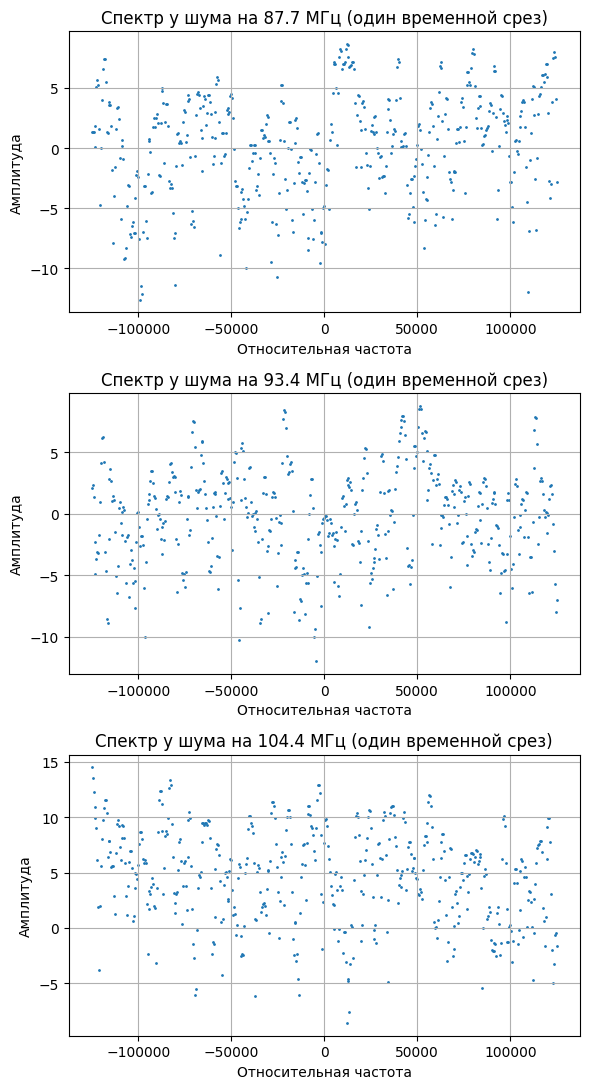

In [31]:
kol_sweep = 0
noise_sample1 = "Noise_87_7"
noise_sample2 = "Noise_93_4"
noise_sample3 = "Noise_104_4"

params = [
    {
        "sample_group_name" : noise_sample1,
        "sweep_idx": kol_sweep,
        "title": f"Спектр у шума на 87.7 МГц (один временной срез)",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    },
    {
        "sample_group_name" : noise_sample2,
        "sweep_idx": kol_sweep,
        "title": f"Спектр у шума на 93.4 МГц (один временной срез)",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    },
    {
        "sample_group_name" : noise_sample3,
        "sweep_idx": kol_sweep,
        "title": f"Спектр у шума на 104.4 МГц (один временной срез)",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    }
]

plotSpectrogramm(df, params)

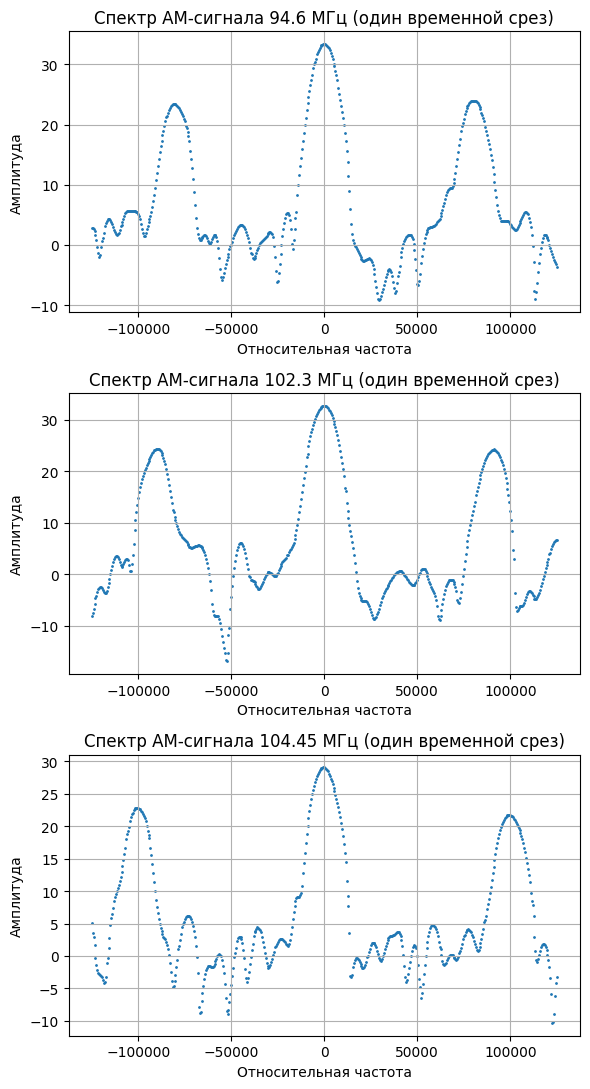

In [32]:
kol_sweep = 0
am_sample1 = "AM_94_6"
am_sample2 = "AM_102_3"
am_sample3 = "AM_104_45"

params = [
    {
        "sample_group_name" : am_sample1,
        "sweep_idx": kol_sweep,
        "title": f"Спектр АМ-сигнала 94.6 МГц (один временной срез)",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    },
    {
        "sample_group_name" : am_sample2,
        "sweep_idx": kol_sweep,
        "title": f"Спектр АМ-сигнала 102.3 МГц (один временной срез)",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    },
    {
        "sample_group_name" : am_sample3,
        "sweep_idx": kol_sweep,
        "title": f"Спектр АМ-сигнала 104.45 МГц (один временной срез)",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    }
]

plotSpectrogramm(df, params)

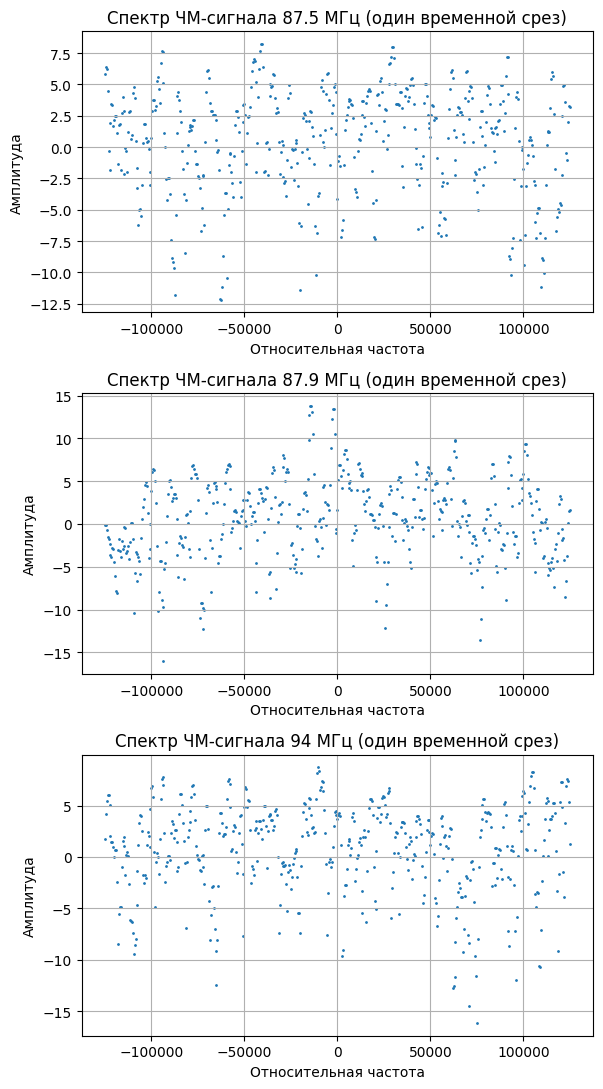

In [33]:
kol_sweep = 0
fm_sample1 = "FM_87_5"
fm_sample2 = "FM_87_9"
fm_sample3 = "FM_94"

params = [
    {
        "sample_group_name" : fm_sample1,
        "sweep_idx": kol_sweep,
        "title": f"Спектр ЧМ-сигнала 87.5 МГц (один временной срез)",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    },
    {
        "sample_group_name" : fm_sample2,
        "sweep_idx": kol_sweep,
        "title": f"Спектр ЧМ-сигнала 87.9 МГц (один временной срез)",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    },
    {
        "sample_group_name" : fm_sample3,
        "sweep_idx": kol_sweep,
        "title": f"Спектр ЧМ-сигнала 94 МГц (один временной срез)",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    }
]

plotSpectrogramm(df, params)

In [7]:
import pandas as pd

from mainFunction import load_all_dataset


def amplitude_statistics_by_dataset(
    df: pd.DataFrame,
    amplitude_col: str = "amplitude_dbm",
    class_col: str = "class_name",
    group_col: str = "sample_group_name",
):
    dataset_stats = (
        df.groupby([class_col, group_col])[amplitude_col]
        .agg(
            mean="mean",
            std="std",
            var="var",
            median="median",
            min="min",
            max="max",
        )
        .reset_index()
    )

    dataset_stats["range"] = dataset_stats["max"] - dataset_stats["min"]

    class_mean_stats = (
        dataset_stats
        .groupby(class_col)
        .mean(numeric_only=True)
        .reset_index()
    )

    return dataset_stats, class_mean_stats


df = load_all_dataset()

dataset_stats, class_mean_stats = amplitude_statistics_by_dataset(df)

print("Статистики по каждому датасету:")
display(dataset_stats)

print("Среднее по статистикам внутри класса:")
display(class_mean_stats)

Статистики по каждому датасету:


,class_name,sample_group_name,mean,std,var,median,min,max,range
0,AM,AM_102_3,5.772486,11.346122,128.734476,2.196315,-27.779266,33.011833,60.791099
1,AM,AM_104_45,5.251330,10.676687,113.991651,2.279640,-27.630417,32.567604,60.198021
2,AM,AM_94_6,6.959975,10.707871,114.658507,3.853478,-23.974930,33.580124,57.555054
3,AM,AM_94_61,11.034662,13.732458,188.580409,5.643578,-20.390160,42.451546,62.841706
4,FM,FM_101_8,7.278013,8.038510,64.617638,5.928021,-22.479477,27.945953,50.425430
5,FM,FM_104_7,6.889980,5.695447,32.438116,6.801903,-19.666344,23.744751,43.411095
6,FM,FM_87_5,0.559622,4.392235,19.291726,0.984657,-23.408279,14.107124,37.515403
7,FM,FM_87_9,1.144930,4.582585,21.000088,1.465256,-20.834541,15.351456,36.185997
8,FM,FM_94,0.410316,4.335789,18.799065,0.798984,-20.848351,12.289597,33.137948
9,FM,FM_94_4,0.554333,4.267132,18.208417,0.941269,-21.843079,12.506386,34.349465


Среднее по статистикам внутри класса:


,class_name,mean,std,var,median,min,max,range
0,AM,7.254613,11.615785,136.491261,3.493253,-24.943693,35.402777,60.346470
1,FM,2.806199,5.218616,29.059175,2.820015,-21.513345,17.657545,39.170890
2,Noise,1.113384,4.310473,18.590524,1.544269,-23.255260,12.988415,36.243675


In [8]:
kol_sweep = 3
am_sample = "AM_102_3"
fm_sample = "FM_101_8"
noise_sample = "Noise_104_4"

params = [
    {
        "sample_group_name" : am_sample,
        "sweep_idx": kol_sweep,
        "title": f"Амплитуда к частоте с усреднением по {kol_sweep} временным промежуткам для {am_sample} МГц",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    },
    {
        "sample_group_name" : fm_sample,
        "sweep_idx": kol_sweep,
        "title": f"Амплитуда к частоте с усреднением по {kol_sweep} временным промежуткам для {fm_sample} МГц",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    },
    {
        "sample_group_name" : noise_sample,
        "sweep_idx": kol_sweep,
        "title": f"Амплитуда к частоте с усреднением по {kol_sweep} временным промежуткам для {noise_sample} МГц",
        "ylabel": "Амплитуда",
        "xlabel": "Относительная частота"
    }
]

stat = pd.DataFrame(columns=["Количество временных промежутков", f"Значение дисперсии для {am_sample}", f"Значение дисперсии для {fm_sample}", f"Значение дисперсии для {noise_sample}"])

for kol_sweep in range(0, 20):

    row = {"Количество временных промежутков": kol_sweep + 1}

    for ind, param in enumerate(params):

        sample_name = param["sample_group_name"]

        mask_amp = (
            (df["sample_group_name"] == sample_name) &
            (df["sweep_idx"] <= kol_sweep)
        )

        amp = (
            df.loc[mask_amp, ["frequency_hz", "amplitude_dbm"]]
            .groupby("frequency_hz")["amplitude_dbm"]
            .mean()
        )

        if ind == 0:
            row[f"Значение дисперсии для {am_sample}"] = amp.var()
        elif ind == 1:
            row[f"Значение дисперсии для {fm_sample}"] = amp.var()
        else:
            row[f"Значение дисперсии для {noise_sample}"] = amp.var()

    stat.loc[len(stat)] = row

In [9]:
stat

,Количество временных промежутков,Значение дисперсии для AM_102_3,Значение дисперсии для FM_101_8,Значение дисперсии для Noise_104_4
0,1,130.803858,71.811847,18.455446
1,2,119.390468,50.215238,10.176251
2,3,122.217328,37.802171,7.253618
3,4,120.764487,32.105497,5.151149
4,5,121.225494,30.041308,4.408903
5,6,122.647547,30.758176,4.239219
6,7,123.198282,28.820423,3.893051
7,8,122.108685,29.267465,3.810306
8,9,120.542681,29.131599,3.496625
9,10,120.561112,28.888832,3.144466


In [10]:
from baseline_logreg import (
    prepare_train_val_datasets,
    train_logistic_regression,
    evaluate_model,
)

prepared = prepare_train_val_datasets(window_size=5)
model = train_logistic_regression(prepared)
metrics = evaluate_model(model, prepared)

print(metrics["accuracy"])
print(metrics["macro_f1"])
print(metrics["classification_report"])
display(metrics["confusion_matrix"])
display(metrics["predictions"])

0.9
0.9074074074074074
              precision    recall  f1-score   support

          AM       1.00      1.00      1.00        10
          FM       1.00      0.80      0.89        20
       Noise       0.71      1.00      0.83        10

    accuracy                           0.90        40
   macro avg       0.90      0.93      0.91        40
weighted avg       0.93      0.90      0.90        40



,pred_AM,pred_FM,pred_Noise
true_AM,10,0,0
true_FM,0,16,4
true_Noise,0,0,10


,class_name,sample_group_name,run_id,sample_id,window_id,window_start_sweep,window_end_sweep,y_true,y_pred
0,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,0,0,4,AM,AM
1,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,1,5,9,AM,AM
2,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,2,10,14,AM,AM
3,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,3,15,19,AM,AM
4,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,4,20,24,AM,AM
5,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,5,25,29,AM,AM
6,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,6,30,34,AM,AM
7,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,7,35,39,AM,AM
8,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,8,40,44,AM,AM
9,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,9,45,49,AM,AM


In [11]:
from baseline_logreg import (
    prepare_train_val_datasets,
    train_random_forest,
    train_gradient_boosting,
    evaluate_model,
)

prepared = prepare_train_val_datasets(window_size=5)

In [12]:
rf_model = train_random_forest(prepared)

rf_metrics = evaluate_model(rf_model, prepared)

print("RF accuracy:", rf_metrics["accuracy"])
print("RF macro-F1:", rf_metrics["macro_f1"])
print(rf_metrics["classification_report"])

display(rf_metrics["confusion_matrix"])
display(rf_metrics["predictions"])

RF accuracy: 0.975
RF macro-F1: 0.9755799755799757
              precision    recall  f1-score   support

          AM       1.00      1.00      1.00        10
          FM       1.00      0.95      0.97        20
       Noise       0.91      1.00      0.95        10

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.98        40
weighted avg       0.98      0.97      0.98        40



,pred_AM,pred_FM,pred_Noise
true_AM,10,0,0
true_FM,0,19,1
true_Noise,0,0,10


,class_name,sample_group_name,run_id,sample_id,window_id,window_start_sweep,window_end_sweep,y_true,y_pred
0,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,0,0,4,AM,AM
1,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,1,5,9,AM,AM
2,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,2,10,14,AM,AM
3,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,3,15,19,AM,AM
4,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,4,20,24,AM,AM
5,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,5,25,29,AM,AM
6,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,6,30,34,AM,AM
7,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,7,35,39,AM,AM
8,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,8,40,44,AM,AM
9,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,9,45,49,AM,AM


In [13]:
gb_model = train_gradient_boosting(prepared)

gb_metrics = evaluate_model(gb_model, prepared)

print("GB accuracy:", gb_metrics["accuracy"])
print("GB macro-F1:", gb_metrics["macro_f1"])
print(gb_metrics["classification_report"])

display(gb_metrics["confusion_matrix"])
display(gb_metrics["predictions"])

GB accuracy: 0.925
GB macro-F1: 0.9229781771501925
              precision    recall  f1-score   support

          AM       1.00      1.00      1.00        10
          FM       0.90      0.95      0.93        20
       Noise       0.89      0.80      0.84        10

    accuracy                           0.93        40
   macro avg       0.93      0.92      0.92        40
weighted avg       0.92      0.93      0.92        40



,pred_AM,pred_FM,pred_Noise
true_AM,10,0,0
true_FM,0,19,1
true_Noise,0,2,8


,class_name,sample_group_name,run_id,sample_id,window_id,window_start_sweep,window_end_sweep,y_true,y_pred
0,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,0,0,4,AM,AM
1,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,1,5,9,AM,AM
2,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,2,10,14,AM,AM
3,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,3,15,19,AM,AM
4,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,4,20,24,AM,AM
5,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,5,25,29,AM,AM
6,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,6,30,34,AM,AM
7,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,7,35,39,AM,AM
8,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,8,40,44,AM,AM
9,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,9,45,49,AM,AM


In [14]:
from mlp_spectrum import (
    prepare_spectrum_vectors,
    train_mlp_spectrum,
    evaluate_mlp,
)

prepared = prepare_spectrum_vectors(
    window_size=5,
    add_binned_features=True,
    bin_stats=("mean", "std", "min", "max", "range", "energy", "slope"),
)

model = train_mlp_spectrum(prepared)
metrics = evaluate_mlp(model, prepared)

print("Accuracy:", metrics["accuracy"])
print("Macro-F1:", metrics["macro_f1"])
print(metrics["classification_report"])
display(metrics["confusion_matrix"])

Accuracy: 0.825
Macro-F1: 0.84
              precision    recall  f1-score   support

          AM       1.00      1.00      1.00        10
          FM       0.93      0.70      0.80        20
       Noise       0.60      0.90      0.72        10

    accuracy                           0.82        40
   macro avg       0.84      0.87      0.84        40
weighted avg       0.87      0.82      0.83        40



,pred_AM,pred_FM,pred_Noise
true_AM,10,0,0
true_FM,0,14,6
true_Noise,0,1,9


In [15]:
from cnn_spectrum import prepare_cnn_arrays, train_cnn, evaluate_cnn

prepared = prepare_cnn_arrays(window_size=5)

model, device = train_cnn(
    prepared,
    epochs=300,
    batch_size=16,
    lr=1e-3,
    weight_decay=3e-4,
    patience=60,
)

metrics = evaluate_cnn(model, device, prepared)

print("Device:", device)
print("Best macro-F1:", model.best_macro_f1)
print("Accuracy:", metrics["accuracy"])
print("Macro-F1:", metrics["macro_f1"])
print(metrics["classification_report"])
display(metrics["confusion_matrix"])

Device: cpu
Best macro-F1: 0.9755799755799757
Accuracy: 0.975
Macro-F1: 0.9755799755799757
              precision    recall  f1-score   support

          AM       1.00      1.00      1.00        10
          FM       1.00      0.95      0.97        20
       Noise       0.91      1.00      0.95        10

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.98        40
weighted avg       0.98      0.97      0.98        40



,pred_AM,pred_FM,pred_Noise
true_AM,10,0,0
true_FM,0,19,1
true_Noise,0,0,10


In [16]:
from cnn2d_spectrum import (
    prepare_cnn2d_arrays,
    train_cnn2d,
    evaluate_cnn2d,
    AugmentationConfig,
)

prepared = prepare_cnn2d_arrays(window_size=5)

augmentation = AugmentationConfig(
    enabled=True,
    shift_prob=0.70,
    max_shift_points=25,
    crop_prob=0.60,
    max_crop_points=60,
    noise_prob=0.25,
    noise_std=0.03,
)

model, device = train_cnn2d(
    prepared,
    epochs=350,
    batch_size=16,
    lr=8e-4,
    weight_decay=5e-4,
    patience=80,
    augmentation=augmentation,
)

metrics = evaluate_cnn2d(model, device, prepared)

print("Device:", device)
print("Best macro-F1:", model.best_macro_f1)
print("Accuracy:", metrics["accuracy"])
print("Macro-F1:", metrics["macro_f1"])
print(metrics["classification_report"])
display(metrics["confusion_matrix"])
display(metrics["predictions"])

Device: cpu
Best macro-F1: 0.9743260590500641
Accuracy: 0.975
Macro-F1: 0.9743260590500641
              precision    recall  f1-score   support

          AM       1.00      1.00      1.00        10
          FM       0.95      1.00      0.98        20
       Noise       1.00      0.90      0.95        10

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



,pred_AM,pred_FM,pred_Noise
true_AM,10,0,0
true_FM,0,20,0
true_Noise,0,1,9


,class_name,sample_group_name,run_id,sample_id,start_sweep_idx,end_sweep_idx,window_size,aggregate,y_true,y_pred
0,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,0,4,5,none,AM,AM
1,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,5,9,5,none,AM,AM
2,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,10,14,5,none,AM,AM
3,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,15,19,5,none,AM,AM
4,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,20,24,5,none,AM,AM
5,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,25,29,5,none,AM,AM
6,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,30,34,5,none,AM,AM
7,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,35,39,5,none,AM,AM
8,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,40,44,5,none,AM,AM
9,AM,AM_102_3,20260514_124354,AM_102_3_20260514_124354_0000,45,49,5,none,AM,AM
